<a href="https://colab.research.google.com/github/JasonWachira/SemProject_MLEngine/blob/main/Model_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Delivery Time Prediction (Pickup → Arrival)
**Task:** Regression — predict how many minutes a motorbike delivery takes from pickup to arrival.
**Base model:** Linear Regression, with Ridge and Lasso regularisation. **Comparison models:** Random Forest, Gradient Boosting.
**Data:** `Train.csv` — motorbike delivery orders in Nairobi.

The notebook follows the data mining process (CRISP-DM):
**1. Business understanding → 2. Data understanding → 3. Data preparation → 4. Modelling → 5. Evaluation → 6. Deployment.**



In [1]:
import os, warnings, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy.stats as st
from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

DATA_PATH = "Train.csv"
RS = 42

## 1. Business understanding
Customers want to know when their parcel will arrive. The goal is to estimate delivery time **at the moment of pickup**, so only information available by then may be used. Success = a lower average error (Mean Absolute Error, in minutes) than simply guessing the average delivery time.

## 2. Data understanding
A first look at size, data types, missing values, duplicates and columns with only one value (which carry no information).

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
miss = df.isna().sum()
display(miss[miss > 0].to_frame("missing").assign(pct=lambda d: (d.missing / len(df) * 100).round(1)))
print("Duplicate orders:", df["Order No"].duplicated().sum(),
      "| Constant columns:", [c for c in df if df[c].nunique() == 1])

Shape: (21201, 29)


,missing,pct
Temperature,4366,20.6
Precipitation in millimeters,20649,97.4


Duplicate orders: 0 | Constant columns: ['Vehicle Type']


**Summary.** Weather columns have gaps (precipitation is mostly blank). `Vehicle Type` is constant, and `Order No` / `User Id` are just identifiers, so none of these help prediction. Each delivery stage has its own day, weekday and time column.

## 3. Data preparation
**3.1 Target and leakage check.** Times are converted to seconds. The target (`Time from Pickup to Arrival`) turns out to equal *arrival time − pickup time*, so the arrival columns would leak the answer and are **excluded**. Instead we keep three gaps that are known before the rider leaves: confirmation delay, time to reach the pickup point, and waiting time at pickup.

In [3]:
stages = ["Placement", "Confirmation", "Arrival at Pickup", "Pickup", "Arrival at Destination"]
for s in stages:
    df[s + "_s"] = (pd.to_datetime(df[s + " - Time"], format="%I:%M:%S %p") - pd.Timestamp("1900-01-01")).dt.total_seconds()

leak = (df["Arrival at Destination_s"] - df["Pickup_s"]) == df["Time from Pickup to Arrival"]
print(f"Target equals (arrival - pickup) in {leak.mean()*100:.1f}% of rows -> arrival columns excluded")

df["target_min"] = df["Time from Pickup to Arrival"] / 60                 # seconds -> minutes
df["conf_lag"]  = df["Confirmation_s"] - df["Placement_s"]                # pre-pickup gaps (seconds)
df["atp_lag"]   = df["Arrival at Pickup_s"] - df["Confirmation_s"]
df["pick_wait"] = df["Pickup_s"] - df["Arrival at Pickup_s"]
df["speed_kmh"] = df["Distance (KM)"] / (df["Time from Pickup to Arrival"] / 3600)

Target equals (arrival - pickup) in 100.0% of rows -> arrival columns excluded


**3.2 Remove invalid records and fill missing values.** Records are dropped if they span different days, have timestamps out of order, or imply an impossible trip (faster than 60 km/h or under 60 seconds — most likely a rider tapping "arrived" without travelling). A blank precipitation value is treated as "no rain" (0 plus a `rain` flag); missing temperature is filled with the median.

In [4]:
bad_day   = df[[s + " - Day of Month" for s in stages]].nunique(axis=1) > 1
bad_order = df["conf_lag"] < 0
bad_speed = (df["speed_kmh"] > 60) | (df["Time from Pickup to Arrival"] < 60)
print(pd.Series({"Cross-day": bad_day.sum(), "Out of order": bad_order.sum(),
                 "Implausible speed/time": bad_speed.sum(), "Total removed": (bad_day | bad_order | bad_speed).sum()}))

clean = df[~(bad_day | bad_order | bad_speed)].copy()
clean["rain"] = clean["Precipitation in millimeters"].notna().astype(int)
clean["Precipitation in millimeters"] = clean["Precipitation in millimeters"].fillna(0)
clean["Temperature"] = clean["Temperature"].fillna(clean["Temperature"].median())
print(f"Rows: {len(df):,} -> {len(clean):,} ({(1 - len(clean)/len(df))*100:.1f}% removed)")

Cross-day                    2
Out of order                 6
Implausible speed/time    1089
Total removed             1096
dtype: int64
Rows: 21,201 -> 20,105 (5.2% removed)


**3.3 Feature engineering.** New inputs are built from the raw columns:
- **Pickup hour** encoded as a circle (sine/cosine) so 23:00 and 00:00 are treated as close together.
- **Straight-line distance** between pickup and destination (haversine formula), alongside the road distance.
- **Business vs personal** order as 0/1, and **platform type** as one-hot (one 0/1 column per category).

`Rider Id` has too many values to use as an input; it is kept only for the rider-grouped check in section 5.

In [5]:
clean["hour"] = (clean["Pickup_s"] // 3600).astype(int)
clean["hour_sin"], clean["hour_cos"] = np.sin(2*np.pi*clean["hour"]/24), np.cos(2*np.pi*clean["hour"]/24)
clean["weekday"]  = clean["Placement - Weekday (Mo = 1)"]
clean["day"]      = clean["Placement - Day of Month"]
clean["business"] = (clean["Personal or Business"] == "Business").astype(int)
a, b, c, d = map(np.radians, [clean["Pickup Lat"], clean["Pickup Long"], clean["Destination Lat"], clean["Destination Long"]])
clean["straight_km"] = 2*6371*np.arcsin(np.sqrt(np.sin((c-a)/2)**2 + np.cos(a)*np.cos(c)*np.sin((d-b)/2)**2))
clean = clean.rename(columns={"Distance (KM)": "distance_km", "Temperature": "temp", "Precipitation in millimeters": "precip_mm",
                              "Pickup Lat": "p_lat", "Pickup Long": "p_lon", "Destination Lat": "d_lat", "Destination Long": "d_lon"})

FEATURES = ["distance_km", "straight_km", "hour_sin", "hour_cos", "weekday", "day", "temp", "precip_mm", "rain",
            "business", "p_lat", "p_lon", "d_lat", "d_lon", "atp_lag", "pick_wait", "conf_lag"]
X = pd.concat([clean[FEATURES], pd.get_dummies(clean["Platform Type"], prefix="platform", drop_first=True).astype(int)], axis=1)
y, groups = clean["target_min"], clean["Rider Id"]
print("Features:", X.shape[1])

Features: 20


**3.4 Explore the prepared data.** Quick checks of what drives delivery time.

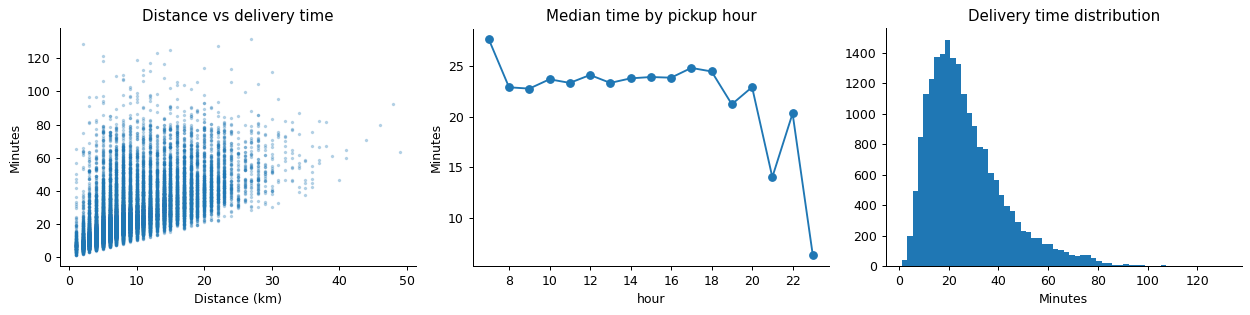

Correlation of each input with delivery time:
{'distance_km': 0.599, 'straight_km': 0.581, 'atp_lag': 0.162, 'p_lon': 0.077, 'd_lon': 0.074, 'p_lat': -0.072}


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].scatter(clean["distance_km"], y, s=3, alpha=.25); ax[0].set(xlabel="Distance (km)", ylabel="Minutes", title="Distance vs delivery time")
clean.groupby("hour")["target_min"].median().plot(ax=ax[1], marker="o"); ax[1].set(title="Median time by pickup hour", ylabel="Minutes")
ax[2].hist(y, bins=60); ax[2].set(title="Delivery time distribution", xlabel="Minutes")
plt.tight_layout(); plt.show()
print("Correlation of each input with delivery time:")
print(X.corrwith(y).sort_values(key=abs, ascending=False).head(6).round(3).to_dict())

In summary distance is the strongest driver, but times vary widely at every distance.

## 4. Modelling
The data is split 80/20 into train and test.

**4.1 Base model — Linear Regression.** It fits a straight-line relationship between the features and the target by estimating coefficients of each feature that shows how much it adds or removes from the target. It is simple, fast and easy to explain. A **naive model** that always predicts the average time is included as the bar to beat.

In [7]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RS)
kf = KFold(5, shuffle=True, random_state=RS)

def evaluate(name, model, cols=None):
    """Cross-validate on train, fit, then score on train and test."""
    Xa, Xb = (X_tr, X_te) if cols is None else (X_tr[cols], X_te[cols])
    cv = -cross_val_score(model, Xa, y_tr, cv=kf, scoring="neg_mean_absolute_error")
    model.fit(Xa, y_tr); p = model.predict(Xb)
    return dict(Model=name, CV_MAE=cv.mean(), Train_MAE=mean_absolute_error(y_tr, model.predict(Xa)),
                Test_MAE=mean_absolute_error(y_te, p), Test_RMSE=mean_squared_error(y_te, p)**.5, Test_R2=r2_score(y_te, p))

ols   = make_pipeline(StandardScaler(), LinearRegression())
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 40)))
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=RS, max_iter=20000))
base_models = {"Naive (mean)": DummyRegressor(), "Linear (OLS)": ols, "Ridge": ridge, "Lasso": lasso}

results = pd.DataFrame([evaluate(n, m) for n, m in base_models.items()]).round(3)
display(results)
print("Ridge alpha:", round(ridge[-1].alpha_, 3), "| Lasso alpha:", round(lasso[-1].alpha_, 4),
      "| Features Lasso switched off:", [f for f, w in zip(X.columns, lasso[-1].coef_) if w == 0])
coef = pd.Series(ridge[-1].coef_, index=X.columns)
print("Largest weights (minutes per standard deviation):", coef.reindex(coef.abs().sort_values(ascending=False).index).head(5).round(2).to_dict())

,Model,CV_MAE,Train_MAE,Test_MAE,Test_RMSE,Test_R2
0,Naive (mean),12.070,12.068,12.148,15.943,-0.000
1,Linear (OLS),8.742,8.731,8.820,12.678,0.368
2,Ridge,8.743,8.732,8.821,12.678,0.368
3,Lasso,8.745,8.733,8.822,12.678,0.368


Ridge alpha: 20.309 | Lasso alpha: 0.0253 | Features Lasso switched off: ['platform_2']
Largest weights (minutes per standard deviation): {'distance_km': 7.47, 'straight_km': 2.19, 'atp_lag': 1.69, 'hour_sin': -0.73, 'p_lon': -0.66}


The linear models should clearly beat the naive model. Similar train, CV and test MAE means the model is stable and not overfitting.

**4.2 Comparison models.** Same data, split and folds, so any difference comes from the model alone:
- **Distance-only linear regression** — shows how much the extra features add beyond distance.
- **Random Forest** — averages many decision trees, each trained on a random sample of the data.
- **Gradient Boosting** — builds trees one after another, each correcting the previous trees' errors.

In [8]:
rf = RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=RS)
gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=RS)
extra = [evaluate("Distance-only linear", make_pipeline(StandardScaler(), LinearRegression()), ["distance_km"]),
         evaluate("Random Forest", rf), evaluate("Gradient Boosting", gb)]
results = pd.concat([results, pd.DataFrame(extra).round(3)], ignore_index=True)
naive_mae = results.loc[results.Model == "Naive (mean)", "Test_MAE"].item()
results["Gain_vs_naive_%"] = ((1 - results["Test_MAE"] / naive_mae) * 100).round(1)
display(results.sort_values("Test_MAE"))

,Model,CV_MAE,Train_MAE,Test_MAE,Test_RMSE,Test_R2,Gain_vs_naive_%
6,Gradient Boosting,8.514,8.176,8.538,12.386,0.396,29.7
5,Random Forest,8.561,7.645,8.573,12.424,0.393,29.4
1,Linear (OLS),8.742,8.731,8.820,12.678,0.368,27.4
2,Ridge,8.743,8.732,8.821,12.678,0.368,27.4
3,Lasso,8.745,8.733,8.822,12.678,0.368,27.4
4,Distance-only linear,8.911,8.910,8.971,12.835,0.352,26.2
0,Naive (mean),12.070,12.068,12.148,15.943,-0.000,0.0


## 5. Evaluation
Three checks on whether the results can be trusted:
1. **Residual diagnostics** — are the base model's errors centred on zero with no pattern? Is there multicollinearity?
2. **Rider-grouped CV** — the same rider can appear in train and test. Grouping folds by rider (a rider is never on both sides) checks the score isn't inflated by this.
3. **Practical accuracy** — what share of predictions land within 5, 10 and 15 minutes of the actual time.

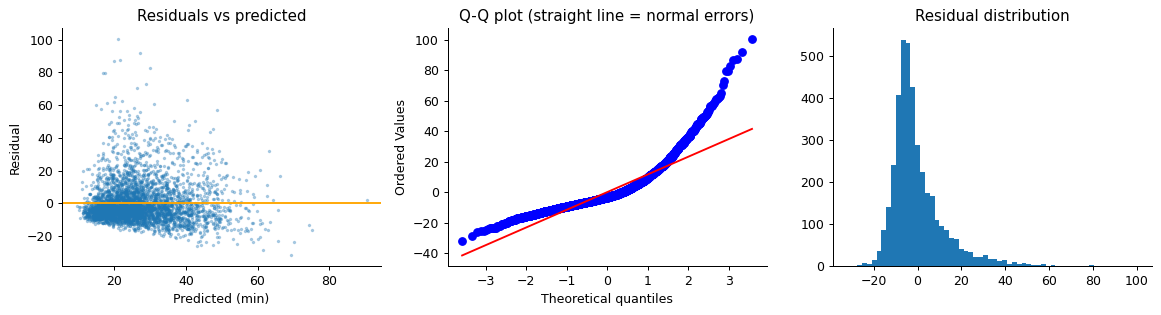

Highest VIF: {'straight_km': 10.9, 'distance_km': 10.8, 'platform_3': 2.7, 'business': 2.4} | Residual skew: 2.11
               Model  Random_CV_MAE  Rider_grouped_MAE
0              Ridge          8.765              8.776
1      Random Forest          8.562              8.568
2  Gradient Boosting          8.521              8.531
Within  5 min: boosting 39.9% | naive 24.6%
Within 10 min: boosting 72.6% | naive 49.3%
Within 15 min: boosting 87.5% | naive 70.5%


In [9]:
# 1. Residuals and VIF for the base model
res = y_te - ridge.predict(X_te)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].scatter(ridge.predict(X_te), res, s=3, alpha=.3); ax[0].axhline(0, color="orange"); ax[0].set(xlabel="Predicted (min)", ylabel="Residual", title="Residuals vs predicted")
st.probplot(res, plot=ax[1]); ax[1].set_title("Q-Q plot (straight line = normal errors)")
ax[2].hist(res, bins=60); ax[2].set_title("Residual distribution"); plt.tight_layout(); plt.show()
Xs = StandardScaler().fit_transform(X_tr)
vif = pd.Series([variance_inflation_factor(Xs, i) for i in range(Xs.shape[1])], index=X.columns)
print("Highest VIF:", vif.sort_values(ascending=False).head(4).round(1).to_dict(), "| Residual skew:", round(st.skew(res), 2))

# 2. Random vs rider-grouped cross-validation
gkf = GroupKFold(5)
print(pd.DataFrame([dict(Model=n,
                         Random_CV_MAE=-cross_val_score(m, X, y, cv=kf, scoring="neg_mean_absolute_error").mean(),
                         Rider_grouped_MAE=-cross_val_score(m, X, y, cv=gkf, groups=groups, scoring="neg_mean_absolute_error").mean())
                    for n, m in {"Ridge": ridge, "Random Forest": rf, "Gradient Boosting": gb}.items()]).round(3))

# 3. Practical accuracy (best model vs naive)
err_gb, err_naive = (y_te - gb.predict(X_te)).abs(), (y_te - y_tr.mean()).abs()
for w in [5, 10, 15]:
    print(f"Within {w:>2} min: boosting {(err_gb <= w).mean()*100:.1f}% | naive {(err_naive <= w).mean()*100:.1f}%")


- **Residuals:** a cloud centred on zero with no curve means a straight-line model fits reasonably. A right-skewed residual histogram means a few deliveries take much longer than predicted.
- **VIF:** road and straight-line distance measure nearly the same thing, so a high VIF there is expected. It doesn't harm predictions, but their individual weights shouldn't be interpreted separately.
- **Grouped CV:** if rider-grouped MAE ≈ random CV MAE, the results aren't inflated by riders appearing in both train and test.
- **Model choice:** if the tree models beat linear regression by only a small margin, the simpler, explainable base model is a defensible choice. The accuracy ceiling then comes from missing information (traffic, route, rider behaviour), not from the type of model.